# Overview of multiclass training meta-estimators: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/multiclass/plot_multiclass_overview.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/multiclass/plot_multiclass_overview.html)).

**Scenario:** a `DecisionTreeClassifier(random_state=0)` alone and wrapped in `OneVsOneClassifier`,
`OneVsRestClassifier` and `OutputCodeClassifier(code_size=2)`, each scored by `cross_validate` over
`RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=0)`; the score densities are plotted.
The second half tunes the tree with `GridSearchCV(max_depth=[3, 5, 8])` inside each wrapper.

**Adaptations**
- Data: the example downloads the OpenML *yeast* dataset (1484 samples, 8 features, 10 imbalanced classes).
  The network is not used here, so `make_classification(n_samples=600, n_features=8, n_informative=5,
  n_redundant=0, n_classes=6, n_clusters_per_class=1, class_sep=0.7, weights=..., random_state=0)`
  stands in: same feature count, several imbalanced classes, a moderately hard problem. Labels are int64.
- `OutputCodeClassifier` gets `random_state=0` on both sides. The example leaves it unseeded, so its codebook
  (and hence its scores) changes per run; seeding makes the comparison exact.
- `cross_validate(..., n_jobs=2)` runs folds sequentially in Moxie; results do not depend on `n_jobs`.
- Moxie wraps its native `moxie.tree.DecisionTreeClassifier` through the dense
  `moxie.feature_selection.DecisionTreeClassifierImportance` adapter, because the tree's own API returns
  `List` probabilities while the multiclass component contract needs `NDArray` ones (see the GAP note).
- Score densities: pandas' `DataFrame.plot.kde` is replaced by `scipy.stats.gaussian_kde` (what pandas calls).

**Determinism:** deterministic. Fold assignment, tree feature permutations (`random_state=0`) and the
seeded codebook are fixed, so per-fold scores must match exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("multiclass/plot_multiclass_overview")

## 1. scikit-learn (Python reference)

The official example code, with the data substitution and the codebook seed described above.

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.stats import gaussian_kde
from sklearn.datasets import make_classification
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier, OutputCodeClassifier
from sklearn.tree import DecisionTreeClassifier

X, y = make_classification(n_samples=600, n_features=8, n_informative=5, n_redundant=0, n_classes=6,
                           n_clusters_per_class=1, class_sep=0.7,
                           weights=[0.3, 0.25, 0.2, 0.12, 0.08, 0.05], random_state=0)
print(pd.Series(y).value_counts().sort_index().to_dict())

cv = RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=0)
tree = DecisionTreeClassifier(random_state=0)
ovo_tree = OneVsOneClassifier(tree)
ovr_tree = OneVsRestClassifier(tree)
ecoc = OutputCodeClassifier(tree, code_size=2, random_state=0)

cv_results_tree = cross_validate(tree, X, y, cv=cv, n_jobs=2)
cv_results_ovo = cross_validate(ovo_tree, X, y, cv=cv, n_jobs=2)
cv_results_ovr = cross_validate(ovr_tree, X, y, cv=cv, n_jobs=2)
cv_results_ecoc = cross_validate(ecoc, X, y, cv=cv, n_jobs=2)
scores = pd.DataFrame({
    "DecisionTreeClassifier": cv_results_tree["test_score"],
    "OneVsOneClassifier": cv_results_ovo["test_score"],
    "OneVsRestClassifier": cv_results_ovr["test_score"],
    "OutputCodeClassifier": cv_results_ecoc["test_score"],
})
folds = [(train, test) for train, test in cv.split(X, y)]
# Learned attributes of one full fit, for attribute-level parity.
full_ovo = OneVsOneClassifier(tree).fit(X, y)
full_ovr = OneVsRestClassifier(tree).fit(X, y)
full_ecoc = OutputCodeClassifier(tree, code_size=2, random_state=0).fit(X, y)
print(scores.mean().round(4).to_dict())
nb.share(X=X, y=y, test_folds=np.array([t for _, t in folds]))

{0: 181, 1: 149, 2: 120, 3: 72, 4: 47, 5: 31}


{'DecisionTreeClassifier': 0.5867, 'OneVsOneClassifier': 0.5943, 'OneVsRestClassifier': 0.5337, 'OutputCodeClassifier': 0.5803}


## 2. Moxie (native Mojo)

The same four models, cross-validated with Moxie's `RepeatedStratifiedKFold` and `cross_val_score`.
The CV adapter is generic over the estimator type: Mojo 1.0 crashes in parameter inference
(`CallParamInf::inferForCall`) when an adapter names a concrete multiclass wrapper type (see the GAP note).

In [3]:
%%mojo overview
from numojo import NDArray, Shape, Item
import numojo as nm
from moxie.base import ClassifierMixin, Predictor
from moxie.multiclass import OneVsRestClassifier, OneVsOneClassifier, OutputCodeClassifier
from moxie.tree import DecisionTreeClassifier
from moxie.feature_selection import DecisionTreeClassifierImportance
from moxie.model_selection import IndexArray, IndexSplit, RepeatedStratifiedKFold, SplitLabels, cross_val_score
from moxie.model_selection._evaluation import TypedScorer
from moxie.model_selection._validation import CVAdapter
from moxie.model_selection._split import _rows
from moxie_nb_io import load, save

comptime Dense = NDArray[DType.float64]
comptime Labels = NDArray[DType.int64]
comptime Tree = DecisionTreeClassifierImportance[DType.float64]


struct Accuracy[E: ClassifierMixin & Predictor & Deinitable](TypedScorer):
    comptime Estimator = Self.E
    comptime Input = Dense
    comptime Target = Labels
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def score(self, estimator: Self.E, X: Dense, y: Labels, metadata: NoneType) raises -> Float64:
        var predicted = rebind_var[Labels](estimator.predict(rebind[Self.E.Input](X)))
        var hits = 0
        for i in range(y.size):
            if predicted.unsafe_get(i) == y.unsafe_get(i):
                hits += 1
        return Float64(hits) / Float64(y.size)


struct Rows[E: ClassifierMixin & Predictor & Deinitable](CVAdapter):
    comptime Scorer = Accuracy[Self.E]

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Labels) raises -> Int:
        return y.size

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Labels, rows: IndexArray) raises -> Labels:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None

    def fit(self, mut estimator: Self.E, X: Dense, y: Labels, metadata: NoneType) raises:
        _ = estimator.fit(rebind[Self.E.Input](X), rebind[Self.E.Target](y))


def cv_scores[E: ClassifierMixin & Predictor & Deinitable](estimator: E, X: Dense, y: Labels, splits: List[IndexSplit]) raises -> Dense:
    return cross_val_score[Rows[E]](estimator, X, y, Rows[E](), Accuracy[E](), splits, None, None)


def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var cursor = RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=0).split(y.size, SplitLabels(y.copy()))
    var splits = List[IndexSplit]()
    var tests = nm.zeros[DType.int64](Shape(15, y.size // 3))
    while True:
        var pair = cursor.next()
        if not pair:
            break
        var k = len(splits)
        for i in range(pair.value().test.size):
            tests[Item(k, i)] = pair.value().test[Item(i)]
        splits.append(pair.value().copy())
    save("test_folds", tests)

    var tree = Tree(DecisionTreeClassifier[DType.int64](random_state=0))
    save("tree", cv_scores(tree.copy(), X, y, splits))
    save("ovo", cv_scores(OneVsOneClassifier(tree.copy()), X, y, splits))
    save("ovr", cv_scores(OneVsRestClassifier(tree.copy()), X, y, splits))
    save("ecoc", cv_scores(OutputCodeClassifier(tree.copy(), code_size=2.0, random_state=0), X, y, splits))

    var ovo = OneVsOneClassifier(tree.copy())
    _ = ovo.fit(X, y)
    save("ovo_classes", ovo.classes_)
    save("ovo_decision", ovo.decision_function(X))
    var ovr = OneVsRestClassifier(tree.copy())
    _ = ovr.fit(X, y)
    save("ovr_proba", ovr.predict_proba(X))
    var ecoc = OutputCodeClassifier(tree.copy(), code_size=2.0, random_state=0)
    _ = ecoc.fit(X, y)
    save("ecoc_code_book", ecoc.code_book_)
    save("ecoc_predict", ecoc.predict(X))
    print("estimators: OvO", len(ovo.estimators_), "| OvR", len(ovr.estimators_), "| ECOC", len(ecoc.estimators_))

estimators: OvO 15 | OvR 6 | ECOC 12


## 3. Side by side and parity

,DecisionTreeClassifier,OneVsOneClassifier,OneVsRestClassifier,OutputCodeClassifier
mean,0.5867,0.5943,0.5337,0.5803
std,0.0374,0.0302,0.0266,0.0310
min,0.5400,0.5400,0.4800,0.5100
max,0.6750,0.6450,0.5850,0.6200
,DecisionTreeClassifier,OneVsOneClassifier,OneVsRestClassifier,OutputCodeClassifier
mean,0.5867,0.5943,0.5337,0.5803
std,0.0374,0.0302,0.0266,0.0310
min,0.5400,0.5400,0.4800,0.5100
max,0.6750,0.6450,0.5850,0.6200


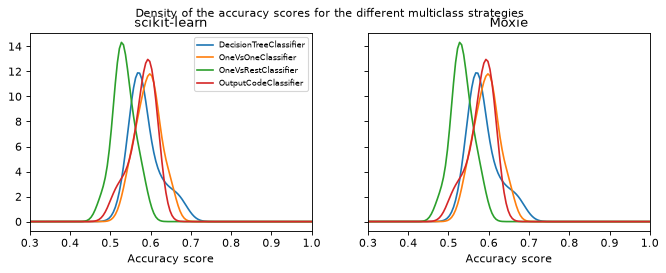

True

In [4]:
mx = nb.results["overview"]
moxie_scores = pd.DataFrame({"DecisionTreeClassifier": mx["tree"], "OneVsOneClassifier": mx["ovo"],
                             "OneVsRestClassifier": mx["ovr"], "OutputCodeClassifier": mx["ecoc"]})
moxie_nb.side_by_side(sklearn=scores.describe().loc[["mean", "std", "min", "max"]].round(4),
                      moxie=moxie_scores.describe().loc[["mean", "std", "min", "max"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), dpi=80, sharey=True)
grid = np.linspace(0, 1, 200)
for ax, frame, title in ((axes[0], scores, "scikit-learn"), (axes[1], moxie_scores, "Moxie")):
    for name in frame:
        ax.plot(grid, gaussian_kde(frame[name])(grid), label=name)
    ax.set_xlabel("Accuracy score")
    ax.set_xlim([0.3, 1.0])
    ax.set_title(title)
axes[0].legend(fontsize=7)
fig.suptitle("Density of the accuracy scores for the different multiclass strategies", fontsize=10)
plt.show()

nb.compare("RepeatedStratifiedKFold test folds", np.sort(np.array([t for _, t in folds]), axis=1),
           np.sort(mx["test_folds"], axis=1), exact=True)
for name in scores:
    nb.compare(f"{name} fold scores", scores[name].to_numpy(), moxie_scores[name].to_numpy(), exact=True)
nb.compare("OvO classes_", full_ovo.classes_, mx["ovo_classes"], exact=True)
nb.compare("OvO decision_function", full_ovo.decision_function(X), mx["ovo_decision"], rtol=1e-14, atol=1e-15,
           reason="votes plus confidence/(3(|confidence|+1)); one division whose rounding may differ in the last ulp")
nb.compare("OvR predict_proba", full_ovr.predict_proba(X), mx["ovr_proba"], rtol=1e-15, atol=1e-15,
           reason="leaf frequencies of identical trees, row-normalized by one division")
nb.compare("ECOC code_book_", full_ecoc.code_book_, mx["ecoc_code_book"], exact=True)
nb.compare("ECOC predict", full_ecoc.predict(X), mx["ecoc_predict"], exact=True)

## 4. Tuned trees inside the wrappers (second half of the example)

The example wraps `GridSearchCV(tree, {"max_depth": [3, 5, 8]}, cv=3)` in each meta-estimator.
Moxie's `GridSearchCV.fit(X, y, fit_metadata, score_metadata)` takes typed metadata arguments and the
search does not conform to `SupervisedEstimator`, so it cannot be a multiclass component. The cell below
shows the compile-time failure.

In [5]:
%%mojo tuned_component --expect-fail
from numojo import NDArray
from moxie.multiclass import OneVsRestClassifier
from moxie.tree import DecisionTreeClassifier
from moxie.feature_selection import DecisionTreeClassifierImportance
from moxie.model_selection import GridSearchCV, IndexArray, IndexSplit, SearchAdapter, SearchScorer, StratifiedKFold
from moxie.model_selection._split import _rows

comptime Dense = NDArray[DType.float64]
comptime Labels = NDArray[DType.int64]
comptime Tree = DecisionTreeClassifierImportance[DType.float64]


struct TreeAccuracy(SearchScorer):
    comptime Estimator = Tree
    comptime Input = Dense
    comptime Target = Labels
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def __init__(out self, *, copy: Self):
        pass

    def score(self, estimator: Tree, X: Dense, y: Labels, metadata: NoneType) raises -> Float64:
        return estimator.score(X, y)


struct DepthSearch(SearchAdapter):
    comptime Scorer = TreeAccuracy
    comptime Value = Int

    def __init__(out self):
        pass

    def __init__(out self, *, copy: Self):
        pass

    def n_samples(self, X: Dense, y: Labels) raises -> Int:
        return y.size

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Labels, rows: IndexArray) raises -> Labels:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None

    def fit(self, mut estimator: Tree, X: Dense, y: Labels, metadata: NoneType) raises:
        _ = estimator.fit(X, y)

    def configure(self, mut estimator: Tree, params: Dict[String, Int]) raises:
        var config = estimator.get_params()
        config.max_depth = params["max_depth"]
        _ = estimator.set_params(config)

    def default_scorer(self) raises -> TreeAccuracy:
        return TreeAccuracy()

    def default_cv(self, X: Dense, y: Labels) raises -> List[IndexSplit]:
        return List[IndexSplit]()


def main() raises:
    var grid = Dict[String, List[Int]]()
    grid["max_depth"] = [3, 5, 8]
    var tree_optimized = GridSearchCV[DepthSearch](Tree(DecisionTreeClassifier[DType.int64](random_state=0)), grid, DepthSearch())
    # sklearn: OneVsRestClassifier(tree_optimized)
    var ovr_tree = OneVsRestClassifier(tree_optimized^)

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/multiclass/plot_multiclass_overview/tuned_component.mojo:71:39: error: no matching function in initialization
    var ovr_tree = OneVsRestClassifier(tree_optimized^)
                   ~~~~~~~~~~~~~~~~~~~^~~~~~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/multiclass/plot_multiclass_overview/tuned_component.mojo:2:
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/multiclass.mojo:12:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/_multiclass_ovr.mojo:143:9: note: candidate not viable: value passed to 'estimator' cannot be converted from 'GridSearchCV[DepthSearch, SearchRefit[DepthSearch.Value]]' to 'E', argument type 'GridSearchCV[DepthSearch, SearchRefit[DepthSearch.Value]]' does not conform to trait 'Predictor & Superv

In [6]:
nb.note("GridSearchCV as a multiclass component", "GAP",
        "GridSearchCV does not conform to SupervisedEstimator (typed metadata fit), so "
        "OneVsRestClassifier/OneVsOneClassifier/OutputCodeClassifier cannot wrap a search; "
        "the second half of the example is not reproduced.")
nb.note("DecisionTreeClassifier as a component", "GAP",
        "the native tree returns List probabilities; wrapping it needs the dense "
        "feature_selection.DecisionTreeClassifierImportance adapter used here.")
nb.note("CV adapter naming a concrete wrapper", "GAP",
        "Mojo 1.0 crashes (CallParamInf::inferForCall) when a CVAdapter/SearchAdapter names a concrete "
        "multiclass wrapper type; adapters generic over the estimator, as above, work.")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
RepeatedStratifiedKFold test folds,PASS,"(15, 200)","(15, 200)",,,exact,0 mismatches,
DecisionTreeClassifier fold scores,PASS,"(15,)","(15,)",,,exact,0 mismatches,
OneVsOneClassifier fold scores,PASS,"(15,)","(15,)",,,exact,0 mismatches,
OneVsRestClassifier fold scores,PASS,"(15,)","(15,)",,,exact,0 mismatches,
OutputCodeClassifier fold scores,PASS,"(15,)","(15,)",,,exact,0 mismatches,
OvO classes_,PASS,"(6,)","(6,)",,,exact,0 mismatches,
OvO decision_function,PASS,"(600, 6)","(600, 6)",0,0,"rtol=1e-14, atol=1e-15",,votes plus confidence/(3(|confidence|+1)); one division whose rounding may differ in the last ulp
OvR predict_proba,PASS,"(600, 6)","(600, 6)",0,0,"rtol=1e-15, atol=1e-15",,"leaf frequencies of identical trees, row-normalized by one division"
ECOC code_book_,PASS,"(6, 12)","(6, 12)",,,exact,0 mismatches,
ECOC predict,PASS,"(600,)","(600,)",,,exact,0 mismatches,
